# RXJ2129 with `glafic_jax`: MAP → SVI → HMC, including w0waCDM cosmology

This notebook models the strong-lensing cluster **RXJ2129** (z = 0.234) from the
catalogues in `example_data/`:

* 38 multiple images of 14 source systems, 0.68 < z_s < 9.5. Three systems
  have photometric redshifts and are sampled with Gaussian priors.
* 144 cluster members with luminosity, ellipticity and position angle.

**Lens model** (glafic models):

| component | glafic model | free parameters |
|---|---|---|
| dark-matter halo | `anfw` (elliptical NFW, CSE approximation) | M, x, y, e, θ, c |
| cluster members | `gals` (pseudo-Jaffe, σ ∝ L^1/4, r_t ∝ L^1/2) | σ*, r_t* |
| external shear | `pert` | γ, θ_γ |
| cosmology | flat **w0waCDM**: w(a) = w0 + wa(1−a), Ω_Λ = 1 − Ω_m | Ω_m, w0, wa |
| source redshifts | systems 12–14 | z_s |

Strong lensing depends on cosmology only through distance ratios
D_ls/D_s. Having many sources at different redshifts behind the same lens is
what makes cluster *cosmography* possible.

**Likelihood.** We use glafic's source-plane χ² (`chi2_splane 1`), which
weights positions by the magnification tensor, so it approximates the
image-plane χ² to first order. The 14 source positions enter quadratically and
are **marginalised analytically** (`source_mode="marginalize"`). This leaves
16 sampled parameters. The full image-plane χ², with glafic's image finder,
is then used as a check of the final model.

**Inference pipeline** (`glafic_jax.Pipeline`):

1. **MAP**: multi-start L-BFGS with exact JAX gradients. We first fix the
   cosmology to ΛCDM to find the lens configuration, then free (Ω_m, w0, wa).
2. **SVI**: a full-rank Gaussian variational posterior, initialised at the MAP.
3. **HMC**: NUTS initialised from SVI draws, using the SVI covariance as the
   starting mass matrix.

In [1]:
import os, sys, time
import numpy as np
import matplotlib.pyplot as plt

HERE = os.path.abspath(".")
REPO = os.path.abspath(os.path.join(HERE, "..", ".."))
try:
    import glafic_jax as gj
except ImportError:                       # not pip-installed: use the repository copy
    sys.path.insert(0, os.path.join(REPO, "python"))
    import glafic_jax as gj
import jax, jax.numpy as jnp
import build_rxj2129 as build

print("jax", jax.__version__, "| devices:", jax.devices())

jax 0.12.0.1 | devices: [CudaDevice(id=0)]


## 1. Data → glafic input files

`build_rxj2129.py` converts RA/Dec to glafic's arcsec coordinates. The origin is
the BCG and x is positive to the west, as in glafic's `coord2xy`. It writes a
normal glafic input file, an observation file, a galaxy file and a prior file,
so the same model can also be run with C glafic.

In [2]:
systems = build.write_all(HERE)
print(open("rxj2129.input").read())
print(open("rxj2129_prior.dat").read())

# glafic input for RXJ2129 (generated by build_rxj2129.py)
omega     0.300000
lambda    0.700000
weos     -1.000000
hubble    0.700000
prefix    rxj2129
xmin     -60.0
ymin     -60.0
xmax      60.0
ymax      60.0
pix_ext   0.2
pix_poi   1.0
maxlev    6
galfile   rxj2129_galfile.dat
chi2_splane    1
chi2_checknimg 0
flatfix   1
ovary     1
wvary     1
wavary    1
hvary     0

startup 3 0 14
lens anfw  0.234 8.0e14  0.0  0.0  0.4  -20.0  6.0  0.0
lens gals  0.234 200.0   0.0  0.0  0.0    0.0 20.0  0.5
lens pert  0.234 2.0     0.0  0.0  0.05  30.0  0.0  0.0
point 0.6790 3.1984 -1.8697
point 0.9160 2.2933 0.6780
point 1.5190 -2.6211 0.4563
point 1.5200 -2.4641 0.0113
point 1.5210 -10.9607 4.3890
point 3.0820 2.3286 1.9817
point 3.4270 4.4777 -3.7337
point 9.5100 -17.7233 7.8884
point 1.5190 -0.5445 5.9040
point 1.5190 0.1760 5.5440
point 1.5190 0.2354 5.2439
point 1.8000 4.1740 -2.5650
point 2.0000 3.6009 1.0109
point 4.2000 1.2893 -6.5925
end_startup

start_setopt
0 1 1 1 1 1 1 0
0 1 0 0 

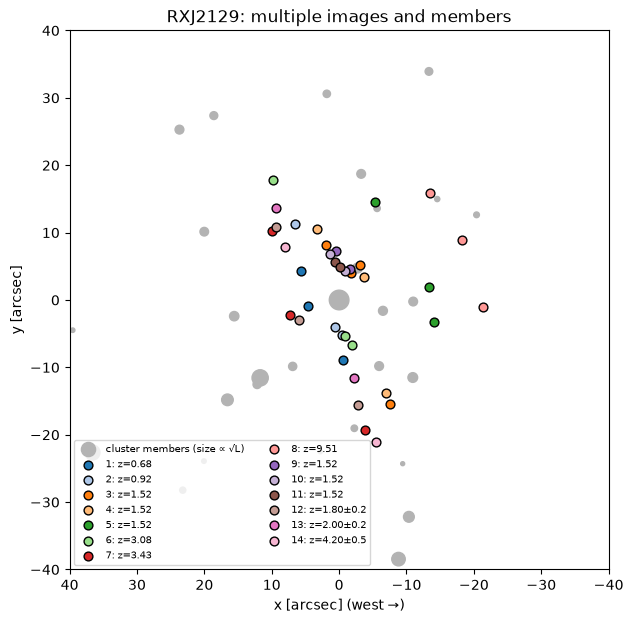

In [3]:
gals = np.loadtxt("rxj2129_galfile.dat")
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(gals[:, 0], gals[:, 1], s=200 * gals[:, 2] ** 0.5, c="0.7", label="cluster members (size ∝ √L)")
cmap = plt.get_cmap("tab20")
for k, (sid, s) in enumerate(systems.items()):
    xy = np.array(s["xy"])
    ax.scatter(xy[:, 0], xy[:, 1], s=40, color=cmap(k % 20), edgecolor="k", zorder=3,
               label=f"{sid}: z={s['zs']:.2f}" + (f"±{s['zerr']:.1f}" if s['zerr'] > 0 else ""))
ax.set_xlim(40, -40); ax.set_ylim(-40, 40); ax.set_aspect("equal")
ax.set_xlabel("x [arcsec] (west →)"); ax.set_ylabel("y [arcsec]")
ax.legend(fontsize=7, ncol=2, loc="lower left"); ax.set_title("RXJ2129: multiple images and members")
plt.show()

## 2. Build the model

Constraints and choices:

* **Cosmology priors** are flat inside the ranges in `rxj2129_prior.dat`:
  Ω_m ∈ [0.05, 1], w0 ∈ [−2.5, 0], wa ∈ [−3, 2]. Flatness is imposed with
  `flatfix 1`.
* **w0 + wa < 0** is added through `extra_log_prior`, so that dark energy is
  subdominant at high redshift. Without it, the z = 9.5 source would sit in a
  universe dominated by dark energy.
* **h** does not affect image positions and is fixed (`hvary 0`).

In [4]:
model = gj.read_input("rxj2129.input")
model.extra_log_prior = lambda P: jnp.where(P["cosmo"][2] + P["cosmo"][4] < 0.0, 0.0, -jnp.inf)
model.set_source_mode("marginalize")
print(model.ndim, "sampled parameters:")
print(model.theta_names)

16 sampled parameters:
['lens1_anfw_p2', 'lens1_anfw_p3', 'lens1_anfw_p4', 'lens1_anfw_p5', 'lens1_anfw_p6', 'lens1_anfw_p7', 'lens2_gals_p2', 'lens2_gals_p7', 'lens3_pert_p5', 'lens3_pert_p6', 'omega', 'weos', 'wa', 'point12_zs', 'point13_zs', 'point14_zs']


## 3. MAP

**Stage 1** fixes ΛCDM (Ω_m = 0.3, w0 = −1, wa = 0) and fits the lens from 12
jittered starting points. The source positions are *profiled* here (set to
their χ²-minimising values), which is the MAP-equivalent of marginalising.
The χ² surface of a cluster model is multimodal, so several starts are needed;
compiled gradients make each start only a few seconds.

**Stage 2** frees (Ω_m, w0, wa) from the stage-1 solution.

In [5]:
for k in ("ovary", "wvary", "wavary"):
    model.set_secondary(f"{k} 0")
model.set_source_mode("profile")
t0 = time.time()
map1 = gj.Pipeline(model).map(n_starts=12, jitter=0.5, seed=0)
model.update_from(model.unflatten(jnp.asarray(map1["theta"])))
chi2_lcdm = map1["chi2"]

for k in ("ovary", "wvary", "wavary"):
    model.set_secondary(f"{k} 1")
model.set_source_mode("profile")
map2 = gj.Pipeline(model).map(n_starts=1)
model.update_from(model.best_sources(model.unflatten(jnp.asarray(map2["theta"]))))
model.model_init()
print(f"\nMAP: chi2(LCDM) = {chi2_lcdm:.3f},  chi2(w0waCDM) = {map2['chi2']:.3f}   [{time.time()-t0:.0f} s total]")
nimg = sum(o["tab"].shape[0] for o in model.obs_point)
print(f"{nimg} images -> {2*nimg} constraints; "
      f"free: {model.ndim} lens/cosmology/z + {2*model.num_poi} source coordinates")
for n, v in zip(model.theta_names, np.asarray(model.theta0())):
    print(f"   {n:16s} {v: .5g}")

[MAP] start 0: chi2 = 1274.59
[MAP] start 1: chi2 = 22.0004
[MAP] start 2: chi2 = 22.0004
[MAP] start 3: chi2 = 22.0004
[MAP] start 4: chi2 = 531.802
[MAP] start 5: chi2 = 951.004
[MAP] start 6: chi2 = 22.0005
[MAP] start 7: chi2 = 22.0004
[MAP] start 8: chi2 = 803.177
[MAP] start 9: chi2 = 22.0004
[MAP] start 10: chi2 = 951.109
[MAP] start 11: chi2 = 550.694
[MAP] best chi2 = 22.0004  (16 s)
[MAP] start 0: chi2 = 19.7048
[MAP] best chi2 = 19.7048  (10 s)

MAP: chi2(LCDM) = 22.000,  chi2(w0waCDM) = 19.705   [45 s total]
38 images -> 76 constraints; free: 16 lens/cosmology/z + 28 source coordinates
   lens1_anfw_p2     1.9093e+15
   lens1_anfw_p3     0.92702
   lens1_anfw_p4    -0.51526
   lens1_anfw_p5     0.47635
   lens1_anfw_p6    -111.53
   lens1_anfw_p7     3.4583
   lens2_gals_p2     179.01
   lens2_gals_p7     199.99
   lens3_pert_p5     0.013072
   lens3_pert_p6    -180
   omega             0.1782
   weos             -2.5
   wa               -2.9998
   point12_zs        1.8906


### Check in the image plane

We solve the lens equation with glafic's adaptive-mesh image finder for every
system at the MAP, and compare the predicted images with the observed ones.

system  1: 3 observed, 3 predicted images; offsets [arcsec] = [0.18 0.29 0.13]
system  2: 3 observed, 3 predicted images; offsets [arcsec] = [0.19 0.17 0.58]
system  3: 4 observed, 3 predicted images; offsets [arcsec] = [0.04 1.54 0.35 0.52]
system  4: 3 observed, 3 predicted images; offsets [arcsec] = [0.08 0.35 0.42]
system  5: 3 observed, 3 predicted images; offsets [arcsec] = [0.47 0.19 0.38]
system  6: 3 observed, 3 predicted images; offsets [arcsec] = [0.34 0.15 0.84]
system  7: 3 observed, 3 predicted images; offsets [arcsec] = [0.26 0.32 0.29]
system  8: 3 observed, 3 predicted images; offsets [arcsec] = [0.09 0.13 0.06]
system  9: 2 observed, 3 predicted images; offsets [arcsec] = [0.16 0.19]
system 10: 2 observed, 3 predicted images; offsets [arcsec] = [0.08 0.08]
system 11: 2 observed, 3 predicted images; offsets [arcsec] = [0.02 0.02]
system 12: 3 observed, 3 predicted images; offsets [arcsec] = [0.29 0.13 0.18]
system 13: 2 observed, 3 predicted images; offsets [arcsec] = 

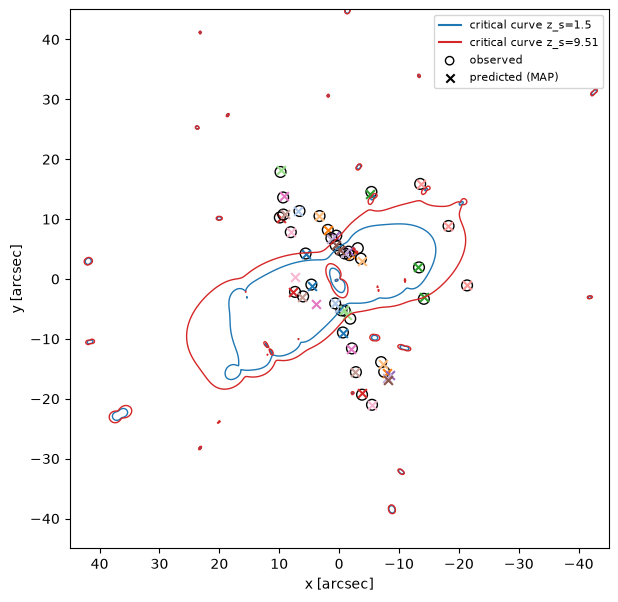

image-plane rms (nearest predicted image) = 0.38 arcsec


In [6]:
P_map = model.params()
rms2, nmatch = [], 0
fig, ax = plt.subplots(figsize=(7, 7))
# critical curves for z_s = 1.5 and 9.5 (|1/mu| -> 0)
g = np.linspace(-45, 45, 451)
X, Y = np.meshgrid(g, g)
for zs, col in ((1.5, "tab:blue"), (9.51, "tab:red")):
    mu = jax.jit(lambda x, y: model.lensmodel(x, y, zs, P_map).muinv)(jnp.asarray(X), jnp.asarray(Y))
    ax.contour(X, Y, np.asarray(mu), levels=[0.0], colors=col, linewidths=1)
    ax.plot([], [], color=col, label=f"critical curve z_s={zs}")
for i in range(model.num_poi):
    obs = model.obs_point[i]["tab"]
    pred = model.findimg(i + 1)
    ax.scatter(obs[:, 0], obs[:, 1], marker="o", facecolor="none", edgecolor="k", s=60)
    ax.scatter(pred[:, 0], pred[:, 1], marker="x", color=cmap(i % 20), s=40)
    for o in obs:   # nearest predicted image
        d2 = ((pred[:, :2] - o[:2]) ** 2).sum(1)
        rms2.append(d2.min()); nmatch += 1
    print(f"system {i+1:2d}: {obs.shape[0]} observed, {pred.shape[0]} predicted images; "
          f"offsets [arcsec] = {np.sqrt([((pred[:, :2]-o[:2])**2).sum(1).min() for o in obs]).round(2)}")
ax.scatter([], [], marker="o", facecolor="none", edgecolor="k", label="observed")
ax.scatter([], [], marker="x", color="k", label="predicted (MAP)")
ax.set_xlim(45, -45); ax.set_ylim(-45, 45); ax.set_aspect("equal"); ax.legend(fontsize=8)
ax.set_xlabel("x [arcsec]"); ax.set_ylabel("y [arcsec]")
plt.show()
print(f"image-plane rms (nearest predicted image) = {np.sqrt(np.mean(rms2)):.2f} arcsec")

For almost all systems the model predicts exactly the observed number of
images, with small image-plane offsets. Where it predicts an extra image,
the extra one is the faint central or counter image that usually goes
unobserved. The one clear failure is image 3.4, which this three-component
model does not produce. A model with a separate BCG component, or
multipoles, would be the natural next step. Everything below uses the
source-plane likelihood.

## 4. SVI

We fit a full-rank Gaussian guide in NumPyro's unconstrained space (every
parameter is mapped from its prior interval to ℝ), initialised at the MAP.

[SVI] final loss 64.7899, median chi2 = 180.407 (56 s)


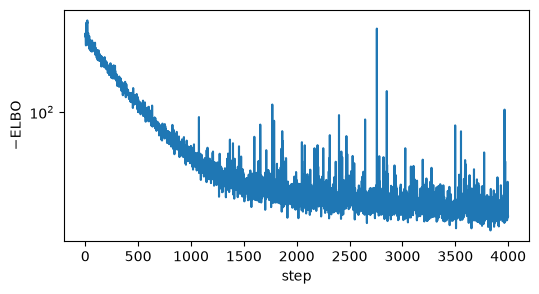

In [7]:
model.set_source_mode("marginalize")
pipe = gj.Pipeline(model)
pipe.results["map"] = dict(theta=np.asarray(model.theta0()), chi2=map2["chi2"], names=model.theta_names)
svi = pipe.svi(num_steps=4000, guide="mvn", lr=5e-3, num_particles=4, num_draws=4000, progress_bar=True)
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(svi["losses"]); ax.set_yscale("symlog"); ax.set_xlabel("step"); ax.set_ylabel("−ELBO")
plt.show()

## 5. HMC (NUTS)

Two chains start from independent SVI draws. The initial dense mass matrix is
the SVI covariance, and is still adapted during warm-up.

In [8]:
hmc = pipe.hmc(num_warmup=500, num_samples=1500, num_chains=2, target_accept=0.85, progress_bar=True)
d = gj.diagnostics(hmc)
print(f"{'parameter':16s} {'mean':>11s} {'std':>10s} {'R-hat':>7s} {'ESS':>7s}")
th = hmc["theta"].reshape(-1, model.ndim)
for k, n in enumerate(d["names"]):
    print(f"{n:16s} {th[:, k].mean():11.4g} {th[:, k].std():10.3g} {d['rhat'][k]:7.3f} {d['ess'][k]:7.0f}")

sample: 100%|██████████| 2000/2000 [10:18<00:00,  3.23it/s]


[HMC] 2 chain(s) x 1500 samples, 1620 divergences, (678 s)
parameter               mean        std   R-hat     ESS
lens1_anfw_p2      4.152e+14   2.98e+14   1.037      84
lens1_anfw_p3          1.235       1.18   1.048      40
lens1_anfw_p4         0.8933       1.75   1.648       2
lens1_anfw_p5          0.594       0.12   1.692       2
lens1_anfw_p6         -106.8       6.27   1.719       2
lens1_anfw_p7          4.175        1.9   1.603       2
lens2_gals_p2          311.1       84.6   2.139       1
lens2_gals_p7          63.68       42.6   1.275       3
lens3_pert_p5         0.1186     0.0603   1.128       6
lens3_pert_p6         -119.8       7.69   1.117       6
omega                 0.5786      0.275   1.013     227
weos                  -1.024      0.765   1.040      80
wa                    -0.824       1.27   1.002     321
point12_zs             1.993      0.128   1.100       5
point13_zs             1.968      0.127   1.083       8
point14_zs             4.206       0.41   1.0

## 6. Cosmology posterior

The corner plot compares HMC (black) with the SVI approximation (orange).
Dashed lines mark ΛCDM.

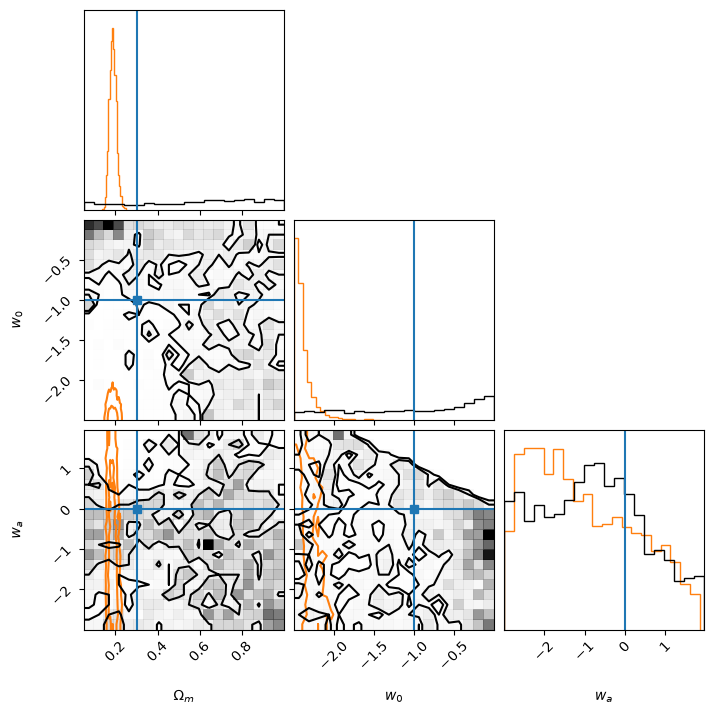

$\Omega_m$   median  0.625   68%: [ 0.232,  0.879]   95%: [ 0.072,  0.979]
$w_0$        median -0.911   68%: [-1.982, -0.176]   95%: [-2.414, -0.024]
$w_a$        median -0.834   68%: [-2.301,  0.512]   95%: [-2.888,  1.679]


In [9]:
import corner
names = model.theta_names
sel = [names.index(n) for n in ("omega", "weos", "wa")]
labels = [r"$\Omega_m$", r"$w_0$", r"$w_a$"]
fig = corner.corner(svi["theta"][:, sel], labels=labels, color="tab:orange", plot_datapoints=False,
                    plot_density=False, levels=(0.68, 0.95), hist_kwargs=dict(density=True))
corner.corner(th[:, sel], fig=fig, labels=labels, color="k", plot_datapoints=False, levels=(0.68, 0.95),
              truths=[0.3, -1.0, 0.0], truth_color="tab:blue", hist_kwargs=dict(density=True))
plt.show()
for k, n in zip(sel, labels):
    q = np.percentile(th[:, k], [2.5, 16, 50, 84, 97.5])
    print(f"{n:12s} median {q[2]: .3f}   68%: [{q[1]: .3f}, {q[3]: .3f}]   95%: [{q[0]: .3f}, {q[4]: .3f}]")

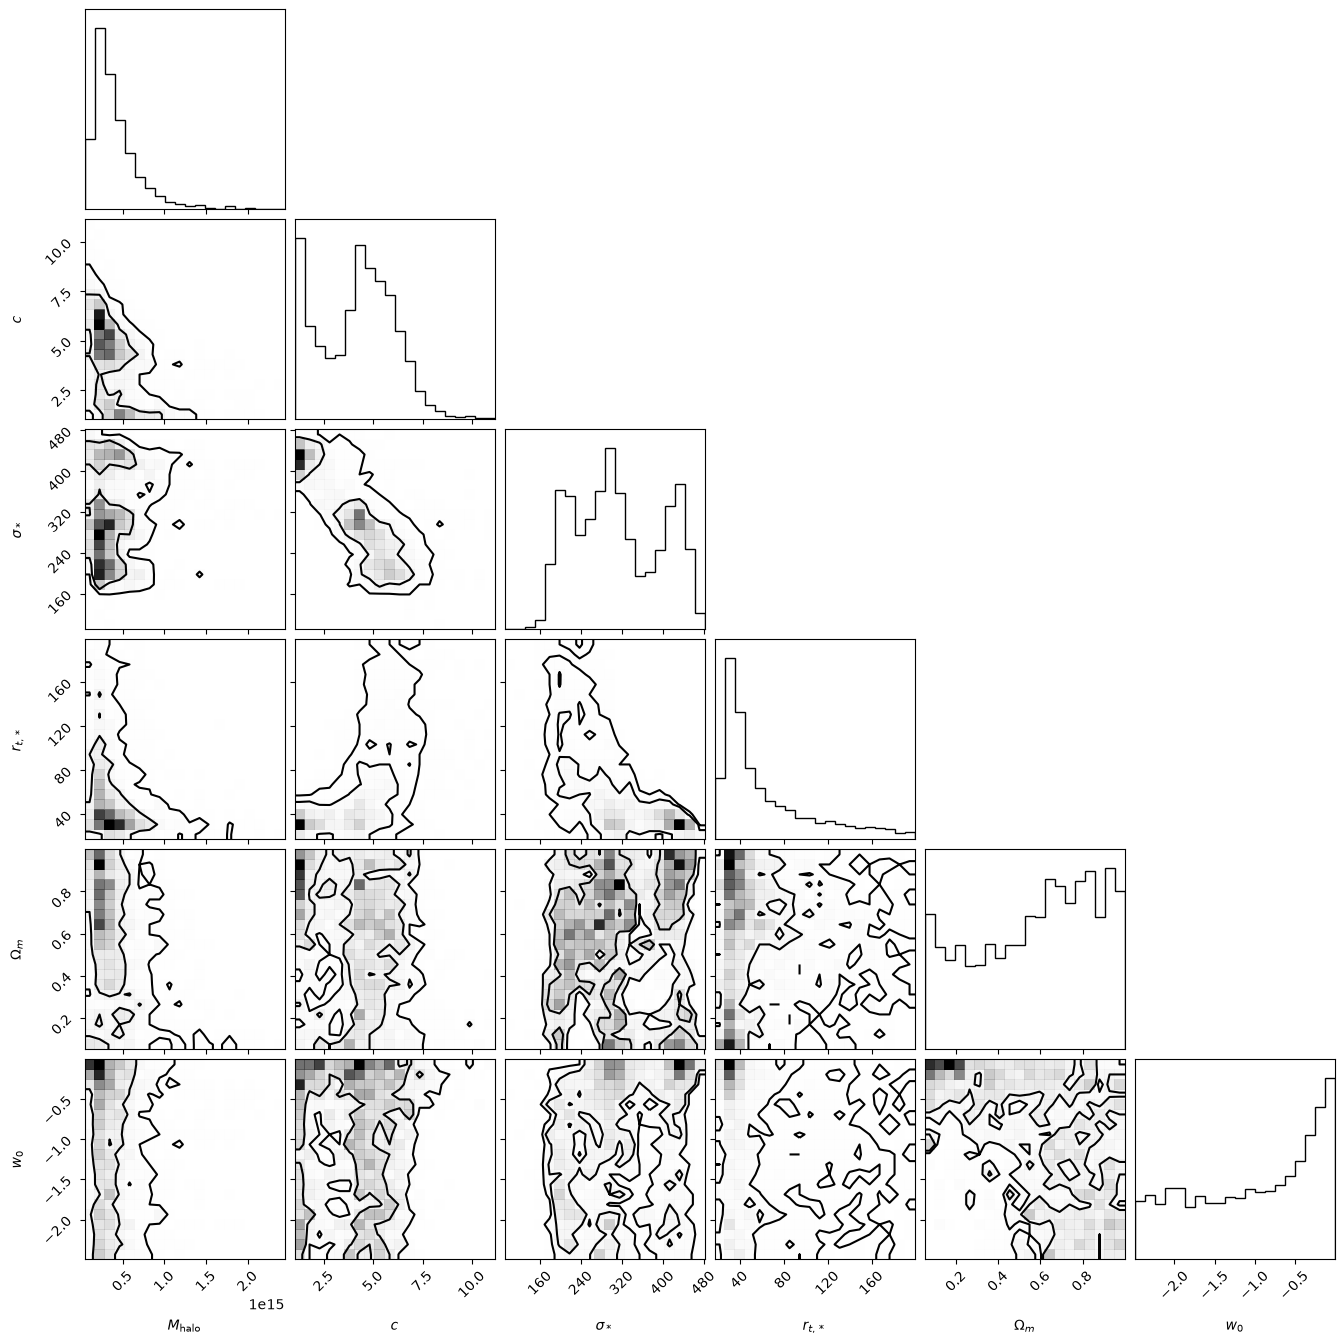

In [10]:
lens_sel = [names.index(n) for n in ("lens1_anfw_p2", "lens1_anfw_p7", "lens2_gals_p2", "lens2_gals_p7", "omega", "weos")]
lab = [r"$M_{\rm halo}$", r"$c$", r"$\sigma_*$", r"$r_{t,*}$", r"$\Omega_m$", r"$w_0$"]
fig = corner.corner(th[:, lens_sel], labels=lab, color="k", plot_datapoints=False, levels=(0.68, 0.95))
plt.show()

## 7. Discussion

* **Pipeline.** The MAP stage finds the lens configuration, SVI gives a
  calibrated Gaussian approximation in seconds, and NUTS refines it. The SVI
  mass matrix means NUTS needs only a short warm-up.
* **Cosmology.** With a single cluster and free (Ω_m, w0, wa), the posterior
  is broad and strongly degenerate with the halo concentration and the
  member-galaxy scaling. The data constrain a combination of distance ratios
  rather than the individual parameters. Compare the HMC contours with the
  prior box: where they reach its edges, the result is prior-dominated.
  Tighter constraints need more spectroscopic systems, a more flexible mass
  model (which inflates the uncertainty further), or several clusters
  combined.
* **Likelihood.** For the final analysis of a system that the model
  reproduces in the image plane, switch to the image-plane χ²:
  `model.set_secondary("chi2_splane 0")` with
  `gj.Pipeline(model, point_mode="tracked")` (pure JAX) or `"glafic"` (exact
  image finding, slower). Use `source_mode="sample"` there.